# Q3 — Invertibilidade das matrizes de covariância

## Dados

In [1]:
import numpy as np
import pandas as pd
from covariancia import mcovar4  # método mais rápido na Q2

df = pd.read_csv("wall+following+robot+navigation+data/sensor_readings_24.data", header=None)
X = df.iloc[:, :24].to_numpy().T  # p x N
y = df[24].to_numpy()

## Matrizes de covariância (global e por classe)

In [2]:
covs = {"Global": mcovar4(X)}
for classe in np.unique(y):
    covs[classe] = mcovar4(X[:, y == classe])

## Posto e número de condicionamento

In [3]:
def rcond(C):
    return 1 / np.linalg.cond(C, 1)  # equivalente ao rcond do Matlab (norma 1)

tabela = pd.DataFrame({
    "N": [X.shape[1]] + [(y == c).sum() for c in list(covs)[1:]],
    "posto": [np.linalg.matrix_rank(C) for C in covs.values()],
    "cond": [np.linalg.cond(C) for C in covs.values()],
    "rcond": [rcond(C) for C in covs.values()],
}, index=list(covs))
tabela

,N,posto,cond,rcond
Global,5456,24,20.548030,0.018819
Move-Forward,2205,24,53.468851,0.007416
Sharp-Right-Turn,2097,24,31.288485,0.012145
Slight-Left-Turn,328,24,173.381572,0.002087
Slight-Right-Turn,826,24,196.173183,0.002255


## Análise visual

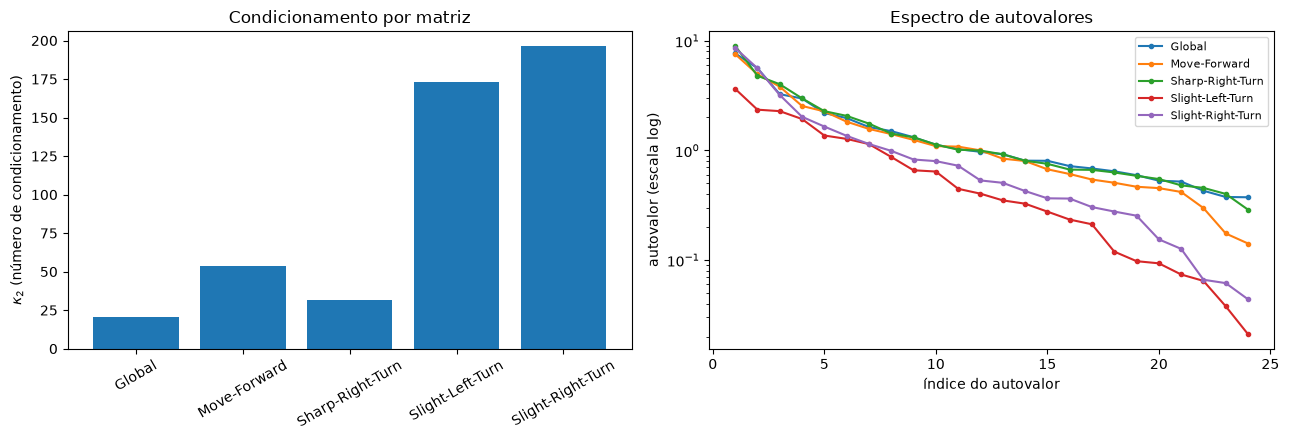

In [4]:
import matplotlib.pyplot as plt

nomes = list(covs)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

# condicionamento por matriz
ax1.bar(nomes, [np.linalg.cond(C) for C in covs.values()], color="tab:blue")
ax1.set_ylabel(r"$\kappa_2$ (número de condicionamento)")
ax1.set_title("Condicionamento por matriz")
ax1.tick_params(axis="x", rotation=30)

# espectro de autovalores (matrizes simétricas -> eigvalsh)
for nome, C in covs.items():
    ev = np.sort(np.linalg.eigvalsh(C))[::-1]
    ax2.semilogy(range(1, len(ev) + 1), ev, marker="o", ms=3, label=nome)
ax2.set_xlabel("índice do autovalor")
ax2.set_ylabel("autovalor (escala log)")
ax2.set_title("Espectro de autovalores")
ax2.legend(fontsize=8)

plt.tight_layout()
plt.show()